In [1]:
print("Hello World")

Hello World


In [2]:
!nvidia-smi

Wed Oct 28 17:30:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!git clone https://github.com/dong-quan-tran/acm-online-learning-human-way.git

Cloning into 'acm-online-learning-human-way'...
remote: Enumerating objects: 242, done.
remote: Counting objects: 100% (242/242), done.
remote: Compressing objects: 100% (200/200), done.
remote: Total 242 (delta 109), reused 93 (delta 33), pack-reused 0 (from 0)
Receiving objects: 100% (242/242), 330.18 KiB | 3.93 MiB/s, done.
Resolving deltas: 100% (109/109), done.


In [4]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # must be set before CUDA initializes

import random
from pathlib import Path

import numpy as np
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

ROOT = Path.cwd() / "acm-online-learning-human-way"   # project-relative, no hard-coded Kaggle path

# ---------- shared settings (team choices; mirror in configs/online.yaml) ----------
CFG = {
    "dataset": "uoft-cs/cifar100",
    "classes": list(range(20)),      # original CIFAR-100 fine-label ids, never remapped
    "num_outputs": 100,              # fixed head for the whole run
    "batch_size": 32,
    "val_fraction": 0.10,            # held out from the training split, per class
    "split_seed": 42,
    "stream_seed": 42,
    "model_seed": 42,
    "optimizer": "AdamW",
    "lr": 5e-4,
    "weight_decay": 5e-4,
    "scheduler": "OneCycleLR",
    "pct_start": 0.15,
    "dropout": 0.2,
    "eval_every": 1000,              # training examples between validation checkpoints
    "eval_batch_size": 256,
    "train_transform": "RandomCrop(32, pad=4, reflect) + RandomHorizontalFlip + ToDtype[0,1]",
    "eval_transform": "ToDtype[0,1]",
    "normalization": "inside the model (CIFAR-100 mean/std); none in the loader",
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)


set_seed(CFG["model_seed"])
hf = load_dataset(CFG["dataset"])
NAMES = hf["train"].features["fine_label"].names
CLASSES = sorted(CFG["classes"])

# ---------- transforms: scale to [0, 1] only; the model does normalization ----------
TRAIN_TF = v2.Compose([
    v2.RandomCrop(32, padding=4, padding_mode="reflect"),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
])
EVAL_TF = v2.ToDtype(torch.float32, scale=True)


# ---------- dataset: original labels + each example's identity ----------
class CifarSubset(Dataset):
    def __init__(self, split, indices, transform):
        sub = hf[split].select(indices.tolist())
        imgs = np.stack([np.array(im.convert("RGB")) for im in sub["img"]])
        self.x = torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous()   # uint8, N x 3 x 32 x 32
        self.y = torch.tensor(sub["fine_label"], dtype=torch.long)          # original CIFAR-100 ids
        self.ids = torch.as_tensor(indices, dtype=torch.long)               # row index in hf[split]
        self.split = split
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.transform(self.x[i]), self.y[i], self.ids[i]


# ---------- hold out validation BEFORE building the stream ----------
def split_train_val(labels, classes, val_fraction, seed):
    rng = np.random.default_rng(seed)
    train_idx, val_idx = [], []
    for c in classes:
        idx = rng.permutation(np.flatnonzero(labels == c))
        n_val = int(round(len(idx) * val_fraction))
        val_idx.append(idx[:n_val])
        train_idx.append(idx[n_val:])
    return np.sort(np.concatenate(train_idx)), np.sort(np.concatenate(val_idx))


train_labels = np.asarray(hf["train"]["fine_label"])
test_labels = np.asarray(hf["test"]["fine_label"])
train_idx, val_idx = split_train_val(train_labels, CLASSES, CFG["val_fraction"], CFG["split_seed"])
test_idx = np.flatnonzero(np.isin(test_labels, CLASSES))

train_ds = CifarSubset("train", train_idx, TRAIN_TF)
val_ds = CifarSubset("train", val_idx, EVAL_TF)
test_ds = CifarSubset("test", test_idx, EVAL_TF)   # official test set: not used during development


# ---------- one combined, shuffled stream ----------
def stream_order(n, seed):
    return torch.randperm(n, generator=torch.Generator().manual_seed(seed))


def make_train_stream(seed=CFG["stream_seed"], batch_size=CFG["batch_size"]):
    order = stream_order(len(train_ds), seed)
    loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        sampler=order.tolist(),                        # fixed recorded order, each example once
        drop_last=False,                               # keep the final smaller batch
        generator=torch.Generator().manual_seed(seed), # seeds augmentation in workers
        num_workers=2,
    )
    return loader, order


def make_eval_loader(ds):
    return DataLoader(ds, batch_size=CFG["eval_batch_size"], shuffle=False, num_workers=2)


train_loader, STREAM_ORDER = make_train_stream()
val_loader = make_eval_loader(val_ds)
test_loader = make_eval_loader(test_ds)

last_batch = len(train_ds) - (len(train_loader) - 1) * CFG["batch_size"]
print(f"classes             : {CLASSES[0]}..{CLASSES[-1]} ({len(CLASSES)} classes, original ids)")
print(f"train / val / test  : {len(train_ds)} / {len(val_ds)} / {len(test_ds)}")
print(f"batch size          : {CFG['batch_size']} -> {len(train_loader)} training batches (last batch {last_batch})")
print(f"split / stream seed : {CFG['split_seed']} / {CFG['stream_seed']}")
print(f"dataset cache       : {os.environ.get('HF_DATASETS_CACHE', '~/.cache/huggingface/datasets')}")

README.md:   0%|          | 0.00/9.98k [00:00<?, ?B/s]

cifar100/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  119MB            

cifar100/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

cifar100/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.8MB            

cifar100/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

classes             : 0..19 (20 classes, original ids)
train / val / test  : 9000 / 1000 / 2000
batch size          : 32 -> 282 training batches (last batch 8)
split / stream seed : 42 / 42
dataset cache       : ~/.cache/huggingface/datasets


In [5]:
def scan(loader):
    ids, ys, sizes = [], [], []
    for x, y, i in loader:
        assert x.dtype == torch.float32 and tuple(x.shape[1:]) == (3, 32, 32), x.shape
        assert x.min() >= 0.0 and x.max() <= 1.0, "loader must scale to [0, 1], not normalize"
        ids.append(i); ys.append(y); sizes.append(len(y))
    return torch.cat(ids), torch.cat(ys), sizes


allowed = set(CLASSES)
tr_ids, tr_y, tr_sizes = scan(make_train_stream()[0])   # fresh loader, train_loader stays untouched
va_ids, va_y, _ = scan(val_loader)
te_ids, te_y, _ = scan(test_loader)

# only selected classes, all of them present, labels not remapped
for name, y in [("train", tr_y), ("val", va_y), ("test", te_y)]:
    assert set(y.tolist()) == allowed, f"{name} labels {sorted(set(y.tolist()))}"
assert torch.equal(tr_y, torch.as_tensor(train_labels[tr_ids.numpy()])), "train labels remapped"

# every training example exactly once, in the recorded order, final small batch kept
assert len(tr_ids) == len(train_ds) == len(set(tr_ids.tolist()))
assert set(tr_ids.tolist()) == set(train_idx.tolist())
assert torch.equal(tr_ids, train_ds.ids[STREAM_ORDER])
assert sum(tr_sizes) == len(train_ds) and tr_sizes[-1] == last_batch

# train and validation come from the same HF split: they must not overlap
assert not set(tr_ids.tolist()) & set(va_ids.tolist()), "train/val overlap"

# same seed -> same order, different seed -> different order
assert torch.equal(stream_order(len(train_ds), CFG["stream_seed"]), STREAM_ORDER)
assert not torch.equal(stream_order(len(train_ds), CFG["stream_seed"] + 1), STREAM_ORDER)
assert torch.equal(scan(make_train_stream()[0])[0], tr_ids)

print("stream checks passed")

stream checks passed


In [6]:
import time
import datetime
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD = (0.2673, 0.2564, 0.2762)


def conv_bn(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
    )


class Residual(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.block = nn.Sequential(conv_bn(c, c), conv_bn(c, c))

    def forward(self, x):
        return x + self.block(x)


class SmallResNet(nn.Module):
    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        self.register_buffer("mean", torch.tensor(CIFAR100_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(CIFAR100_STD).view(1, 3, 1, 1))
        self.features = nn.Sequential(
            conv_bn(3, 64), Residual(64), nn.MaxPool2d(2),
            conv_bn(64, 128), Residual(128), nn.MaxPool2d(2),
            conv_bn(128, 256), Residual(256), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(256, num_classes))

    @property
    def num_classes(self):
        return self.classifier[1].out_features

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.features(x).mean(dim=(2, 3))
        return self.classifier(x)


def state_snapshot(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items()}


@torch.no_grad()
def evaluate(model, loader):
    """Accuracy over all outputs (no task masks). Verifies the model is unchanged."""
    was_training = model.training
    before = state_snapshot(model)
    model.eval()
    correct = n = 0
    for x, y, _ in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        n += len(y)
    for k, v in model.state_dict().items():          # weights and BatchNorm statistics
        assert torch.equal(v, before[k]), f"evaluation changed {k}"
    model.train(was_training)
    return correct / n


def run_online(cfg, train_loader, val_loader, n_train):
    set_seed(cfg["model_seed"])
    model = SmallResNet(num_classes=cfg["num_outputs"], dropout=cfg["dropout"]).to(device)
    with torch.no_grad():
        assert model(torch.zeros(2, 3, 32, 32, device=device)).shape == (2, cfg["num_outputs"])

    # created once, never reset; schedule sized to this single pass
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=cfg["lr"], total_steps=len(train_loader), pct_start=cfg["pct_start"]
    )

    run_id = (f"online_c{len(cfg['classes'])}_m{cfg['model_seed']}_s{cfg['stream_seed']}_"
              f"{datetime.datetime.now():%Y%m%d-%H%M%S}")
    rows = []
    seen = updates = 0
    eval_seconds = 0.0
    loss_sum, loss_n = 0.0, 0
    t_start = None

    def checkpoint():
        nonlocal eval_seconds, loss_sum, loss_n
        t0 = time.perf_counter()
        acc = evaluate(model, val_loader)
        eval_seconds += time.perf_counter() - t0
        train_s = 0.0 if t_start is None else time.perf_counter() - t_start - eval_seconds
        rows.append({
            "mode": "online",
            "run_id": run_id,
            "model_seed": cfg["model_seed"],
            "stream_seed": cfg["stream_seed"],
            "num_classes": len(cfg["classes"]),
            "examples_processed": seen,
            "updates": updates,
            "passes": seen / n_train,
            "batch_size": cfg["batch_size"],
            "learning_rate": cfg["lr"],
            "optimizer": cfg["optimizer"],
            "eval_split": "validation",
            "accuracy": acc,
            "training_seconds": train_s,
        })
        avg_loss = loss_sum / loss_n if loss_n else float("nan")
        print(f"  examples {seen:6d} | updates {updates:5d} | train loss {avg_loss:.3f} | val acc {acc:.3f}")
        loss_sum, loss_n = 0.0, 0

    checkpoint()                                    # before any training
    next_eval = cfg["eval_every"]
    model.train()
    t_start = time.perf_counter()
    eval_seconds = 0.0                              # pre-training eval is not part of training time

    for x, y, _ in train_loader:                    # one pass: each batch arrives once
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        scheduler.step()

        seen += len(y)
        updates += 1
        loss_sum += loss.item() * len(y)
        loss_n += len(y)

        if seen >= next_eval or seen == n_train:    # record the actual count when a batch crosses
            checkpoint()
            while next_eval <= seen:
                next_eval += cfg["eval_every"]

    assert seen == n_train, f"processed {seen}, stream has {n_train}"
    assert updates == len(train_loader), f"{updates} updates for {len(train_loader)} batches"
    assert rows[-1]["passes"] == 1.0
    return model, rows, run_id


print(f"Online run: {len(CLASSES)} classes, single pass, batch {CFG['batch_size']}, device {device}")
model, ROWS, RUN_ID = run_online(CFG, train_loader, val_loader, len(train_ds))
print(f"final validation accuracy: {ROWS[-1]['accuracy']:.3f}  ({RUN_ID})")

Online run: 20 classes, single pass, batch 32, device cuda
  examples      0 | updates     0 | train loss nan | val acc 0.000
  examples   1024 | updates    32 | train loss 3.982 | val acc 0.156
  examples   2016 | updates    63 | train loss 2.737 | val acc 0.214
  examples   3008 | updates    94 | train loss 2.531 | val acc 0.252
  examples   4000 | updates   125 | train loss 2.442 | val acc 0.284
  examples   5024 | updates   157 | train loss 2.306 | val acc 0.316
  examples   6016 | updates   188 | train loss 2.198 | val acc 0.378
  examples   7008 | updates   219 | train loss 2.045 | val acc 0.418
  examples   8000 | updates   250 | train loss 1.974 | val acc 0.420
  examples   9000 | updates   282 | train loss 2.002 | val acc 0.432
final validation accuracy: 0.432  (online_c20_m42_s42_20261028-173041)


In [7]:
import csv
import json
import platform
import sys
import yaml

RESULTS_DIR = ROOT / "results"
RUNS_DIR = RESULTS_DIR / "runs"
CONFIG_DIR = ROOT / "configs"
CKPT_DIR = ROOT / "checkpoints"        # local only; make sure checkpoints/ is in .gitignore
for d in (RESULTS_DIR, RUNS_DIR, CONFIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

FIELDS = ["mode", "run_id", "model_seed", "stream_seed", "num_classes", "examples_processed",
          "updates", "passes", "batch_size", "learning_rate", "optimizer", "eval_split",
          "accuracy", "training_seconds"]

csv_path = RESULTS_DIR / "online_results.csv"
new_file = not csv_path.exists() or csv_path.stat().st_size == 0
existing_runs = set()
if not new_file:
    with open(csv_path, newline="") as f:
        existing_runs = {r["run_id"] for r in csv.DictReader(f)}

if RUN_ID in existing_runs:
    print(f"{RUN_ID} already in {csv_path.name}; not appending again")
else:
    with open(csv_path, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new_file:
            w.writeheader()
        for r in ROWS:
            assert 0.0 <= r["accuracy"] <= 1.0
            w.writerow(r)

# shared settings
with open(CONFIG_DIR / "online.yaml", "w") as f:
    yaml.safe_dump(CFG, f, sort_keys=False)

# per-run record, linked from the CSV by run_id
run_meta = {
    "run_id": RUN_ID,
    "setting": "online: mixed-class shuffled stream, single pass, one update per batch, no replay",
    "config": CFG,
    "n_train": len(train_ds), "n_val": len(val_ds), "n_test_reserved": len(test_ds),
    "n_batches": len(train_loader),
    "device": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
    "versions": {
        "python": sys.version.split()[0], "platform": platform.platform(),
        "torch": str(torch.__version__), "numpy": str(np.__version__),
        "datasets": str(__import__("datasets").__version__),
        "torchvision": str(__import__("torchvision").__version__),
    },
    "command": "Run all cells of the online-learning notebook (no edits)",
}
with open(RUNS_DIR / f"{RUN_ID}.yaml", "w") as f:
    yaml.safe_dump(run_meta, f, sort_keys=False)

# validation membership and stream order (metadata only, no images)
with open(RUNS_DIR / f"{RUN_ID}_split.json", "w") as f:
    json.dump({
        "split_seed": CFG["split_seed"], "stream_seed": CFG["stream_seed"],
        "val_train_split_rows": val_idx.tolist(),
        "stream_train_split_rows": train_ds.ids[STREAM_ORDER].tolist(),
    }, f)

# final model, local only
torch.save(
    {"model": model.state_dict(), "config": CFG, "run_id": RUN_ID,
     "setting": run_meta["setting"], "results": ROWS},
    CKPT_DIR / f"{RUN_ID}.pt",
)

print(f"appended {len(ROWS)} rows to {csv_path.relative_to(ROOT)}")
print(f"config: configs/online.yaml | run record: results/runs/{RUN_ID}.yaml")

appended 10 rows to results/online_results.csv
config: configs/online.yaml | run record: results/runs/online_c20_m42_s42_20261028-173041.yaml


In [8]:
%ls /kaggle/working/acm-online-learning-human-way/checkpoints

online_c20_m42_s42_20261028-173041.pt


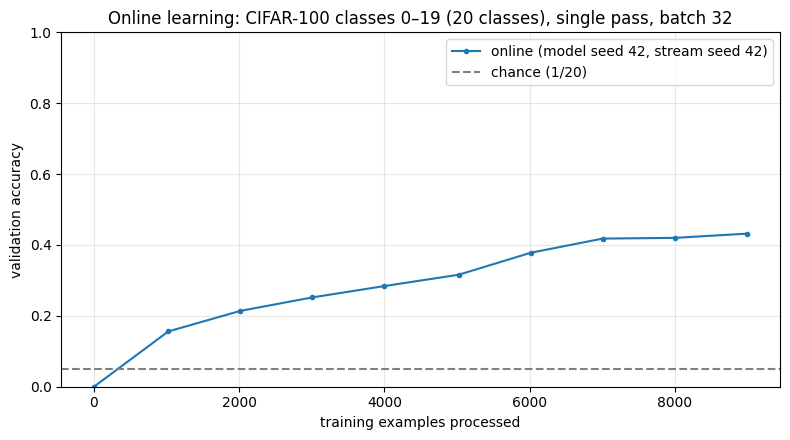

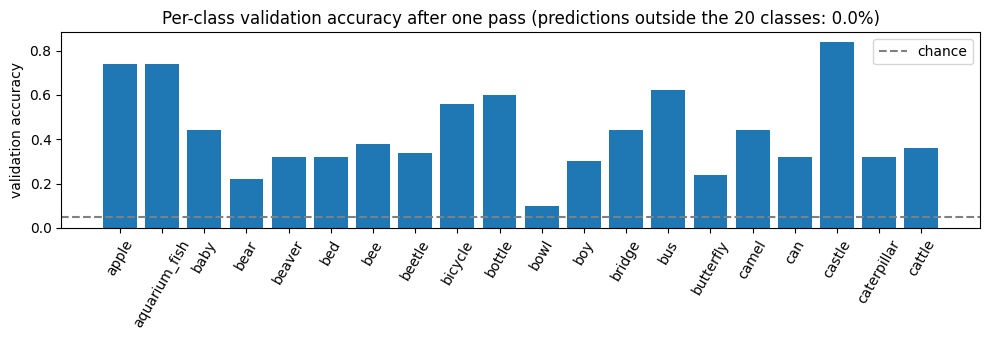

In [9]:
import matplotlib.pyplot as plt

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 1. learning curve: validation accuracy vs training examples processed
xs = [r["examples_processed"] for r in ROWS]
ys = [r["accuracy"] for r in ROWS]
plt.figure(figsize=(8, 4.5))
plt.plot(xs, ys, marker="o", ms=3, label=f"online (model seed {CFG['model_seed']}, stream seed {CFG['stream_seed']})")
plt.axhline(1 / len(CLASSES), color="gray", ls="--", label=f"chance (1/{len(CLASSES)})")
plt.xlabel("training examples processed")
plt.ylabel("validation accuracy")
plt.title(f"Online learning: CIFAR-100 classes {CLASSES[0]}–{CLASSES[-1]} "
          f"({len(CLASSES)} classes), single pass, batch {CFG['batch_size']}")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "online_learning_curve.png", dpi=150)
plt.show()


# 2. per-class validation accuracy at the end of the pass
@torch.no_grad()
def predict(model, loader):
    model.eval()
    P, Y = [], []
    for x, y, _ in loader:
        P.append(model(x.to(device)).argmax(1).cpu())
        Y.append(y)
    return torch.cat(P), torch.cat(Y)


p, y = predict(model, val_loader)
per_class = [(p[y == c] == c).float().mean().item() for c in CLASSES]
outside = (~torch.isin(p, torch.tensor(CLASSES))).float().mean().item()

plt.figure(figsize=(10, 3.5))
plt.bar(range(len(CLASSES)), per_class)
plt.axhline(1 / len(CLASSES), color="gray", ls="--", label="chance")
plt.xticks(range(len(CLASSES)), [NAMES[c] for c in CLASSES], rotation=60)
plt.ylabel("validation accuracy")
plt.title(f"Per-class validation accuracy after one pass "
          f"(predictions outside the {len(CLASSES)} classes: {outside:.1%})")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import time, datetime
from sklearn.linear_model import SGDClassifier

# Same rows, same recorded order, same batch size as the baseline stream,
# but EVAL_TF instead of TRAIN_TF: raw pixels scaled to [0,1], no crop/flip.
sgd_train_ds = CifarSubset("train", train_idx, EVAL_TF)
sgd_loader = DataLoader(sgd_train_ds, batch_size=CFG["batch_size"],
                        sampler=STREAM_ORDER.tolist(), drop_last=False, num_workers=2)

def flat(x):                                    # (N,3,32,32) in [0,1] -> (N,3072)
    return x.reshape(len(x), -1).numpy()

X_val = flat(val_ds.x.float() / 255.0)           # same scaling as EVAL_TF
y_val = val_ds.y.numpy()

clf = SGDClassifier(loss="log_loss", random_state=CFG["model_seed"], shuffle=False)
n_train = len(sgd_train_ds)
SGD_RUN_ID = (f"sgd_c{len(CLASSES)}_m{CFG['model_seed']}_s{CFG['stream_seed']}_"
              f"{datetime.datetime.now():%Y%m%d-%H%M%S}")
SGD_ROWS, seen, updates, train_s = [], 0, 0, 0.0

def sgd_checkpoint():
    acc = float((clf.predict(X_val) == y_val).mean())
    SGD_ROWS.append({
        "mode": "online_sgd", "run_id": SGD_RUN_ID,
        "model_seed": CFG["model_seed"], "stream_seed": CFG["stream_seed"],
        "num_classes": len(CLASSES), "examples_processed": seen, "updates": updates,
        "passes": seen / n_train, "batch_size": CFG["batch_size"],
        "learning_rate": "optimal", "optimizer": "SGDClassifier(log_loss)",
        "eval_split": "validation", "accuracy": acc, "training_seconds": train_s,
    })
    print(f"  examples {seen:6d} | updates {updates:5d} | val acc {acc:.3f}")

next_eval = CFG["eval_every"]
for x, y, _ in sgd_loader:                       # one pass, each batch once, no replay
    X, y = flat(x), y.numpy()
    t0 = time.perf_counter()
    if updates == 0:
        clf.partial_fit(X, y, classes=np.array(CLASSES))   # full class list, first call only
    else:
        clf.partial_fit(X, y)                               # same model, never re-created
    train_s += time.perf_counter() - t0
    seen += len(y); updates += 1
    if seen >= next_eval or seen == n_train:     # same checkpoint rule as run_online
        sgd_checkpoint()
        while next_eval <= seen:
            next_eval += CFG["eval_every"]

assert seen == n_train and updates == len(sgd_loader)

# Evaluation counts must match the CNN baseline (excluding its pre-training row at 0)
if "ROWS" in globals():
    assert [r["examples_processed"] for r in ROWS[1:]] == \
           [r["examples_processed"] for r in SGD_ROWS], "eval counts differ from baseline"

print(f"final validation accuracy: {SGD_ROWS[-1]['accuracy']:.3f}  ({SGD_RUN_ID})")

  examples   1024 | updates    32 | val acc 0.101
  examples   2016 | updates    63 | val acc 0.136
  examples   3008 | updates    94 | val acc 0.168
  examples   4000 | updates   125 | val acc 0.132
  examples   5024 | updates   157 | val acc 0.117
  examples   6016 | updates   188 | val acc 0.179
  examples   7008 | updates   219 | val acc 0.157
  examples   8000 | updates   250 | val acc 0.185
  examples   9000 | updates   282 | val acc 0.124
final validation accuracy: 0.124  (sgd_c20_m42_s42_20261028-173054)


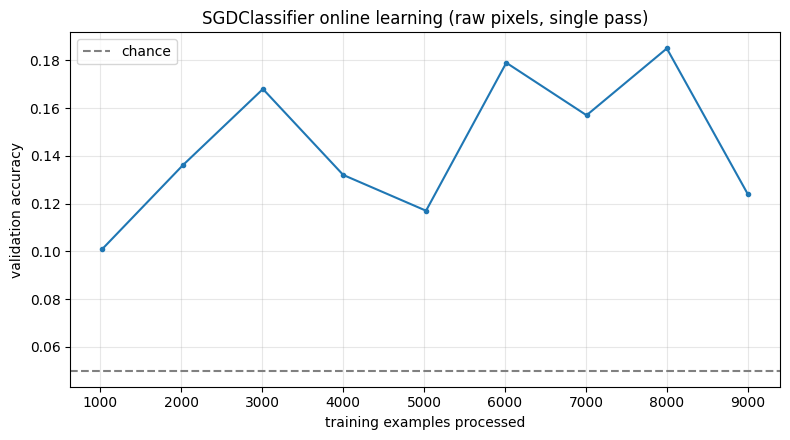

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5))
plt.plot([r["examples_processed"] for r in SGD_ROWS], [r["accuracy"] for r in SGD_ROWS],
         marker="o", ms=3)
plt.axhline(1 / len(CLASSES), color="gray", ls="--", label="chance")
plt.xlabel("training examples processed")
plt.ylabel("validation accuracy")
plt.title("SGDClassifier online learning (raw pixels, single pass)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()